# 04. 실제 데이터 이상 탐지 (수집 중간 결과)
**데이터**: 허브 유동인구(583) 2024-04-01~07-31 — 쿼터 때문에 끝까지 받은 달만 사용(4개월, 83,935행 = 122일×688행). 나머지 기간은 수집이 끝나면 같은 코드로 다시 실행한다.

**방법** (`app/analytics/detect.py`)
- `seasonal_z`: 같은 요일 앞뒤 4주 값의 중앙값을 기대값으로, 잔차를 MAD로 표준화한 점수
- `robust_resid`: STL(주기 7, seasonal=13, trend=29) 분해 잔차를 MAD로 표준화
- 수집되지 않은 날은 이상으로 보지 않음, 연속 이상일은 '구간'으로 묶음(3일 이상 = 지속 변화)

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False

In [2]:
from app.store.cache import CacheStore
from app.analytics.detect import detect_anomalies, group_episodes
st = CacheStore("data/cache")
rows, eps = [], []
for emd in st.regions("유동인구"):
    s = st.series("유동인구", emd)
    for m in ["seasonal_z", "robust_resid"]:
        found = detect_anomalies(s, method=m, threshold=3.5)
        rows += [{"읍면동": emd, "방법": m, "날짜": a.date.date(), "기대 대비(%)": round(a.pct * 100, 1), "점수": round(a.score, 1)} for a in found]
        eps += [{"읍면동": emd, "방법": m, "시작": e.start.date(), "끝": e.end.date(), "일수": e.days, "유형": e.kind,
                 "최대일": e.peak.date.date(), "기대 대비(%)": round(e.peak.pct * 100, 1), "점수": round(e.peak.score, 1)} for e in group_episodes(found)]
an, ep = pd.DataFrame(rows), pd.DataFrame(eps)
print(f"읍면동 {an['읍면동'].nunique()}곳 · 방법별 이상일:", an.groupby("방법").size().to_dict(), "· 방법별 구간:", ep.groupby("방법").size().to_dict())
both = an.pivot_table(index=["읍면동", "날짜"], columns="방법", values="점수").dropna()
print("두 방법이 모두 잡은 이상일:", len(both))

읍면동 43곳 · 방법별 이상일: {'robust_resid': 320, 'seasonal_z': 179} · 방법별 구간: {'robust_resid': 208, 'seasonal_z': 80}
두 방법이 모두 잡은 이상일: 128


## 이상일이 많이 겹친 날 — 여러 읍면동이 동시에 움직인 날은 제주 전체 요인(연휴·성수기) 가능성

In [3]:
top_days = an[an["방법"] == "seasonal_z"]["날짜"].value_counts().head(8).rename_axis("날짜").reset_index(name="이상 읍면동 수")
from app.analytics.context import KR_HOLIDAYS
top_days["공휴일"] = top_days["날짜"].map(lambda d: KR_HOLIDAYS.get(d, ""))
top_days

,날짜,이상 읍면동 수,공휴일
0,2024-07-31,32,
1,2024-07-30,31,
2,2024-07-29,27,
3,2024-07-28,19,
4,2024-06-07,14,
5,2024-05-06,12,어린이날 대체 휴일
6,2024-05-05,7,어린이날
7,2024-07-26,5,


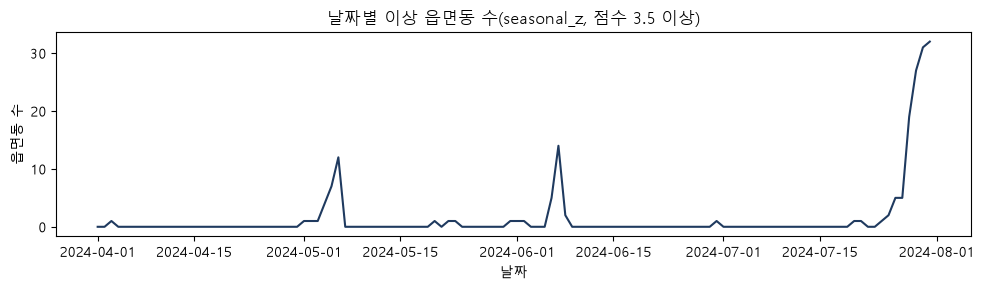

In [4]:
daily = an[an["방법"] == "seasonal_z"].groupby("날짜").size().reindex(pd.date_range("2024-04-01", "2024-07-31").date, fill_value=0)
ax = daily.plot(figsize=(10, 3), color="#1F3A5F", title="날짜별 이상 읍면동 수(seasonal_z, 점수 3.5 이상)")
ax.set_ylabel("읍면동 수"); plt.tight_layout()

## 점수가 큰 이상 구간 상위 10개 (seasonal_z)

In [5]:
ep[ep["방법"] == "seasonal_z"].sort_values("점수", key=abs, ascending=False).head(10).reset_index(drop=True)

,읍면동,방법,시작,끝,일수,유형,최대일,기대 대비(%),점수
0,제주시 이호동,seasonal_z,2024-07-26,2024-07-29,4,지속 변화,2024-07-28,116.2,15.4
1,제주시 애월읍,seasonal_z,2024-07-24,2024-07-31,8,지속 변화,2024-07-31,101.0,13.4
2,제주시 한림읍,seasonal_z,2024-07-25,2024-07-31,7,지속 변화,2024-07-31,128.5,9.1
3,서귀포시 안덕면,seasonal_z,2024-07-28,2024-07-31,4,지속 변화,2024-07-31,114.0,8.8
4,제주시 건입동,seasonal_z,2024-07-28,2024-07-31,4,지속 변화,2024-07-31,49.4,8.2
5,제주시 조천읍,seasonal_z,2024-07-27,2024-07-31,5,지속 변화,2024-07-31,104.8,8.2
6,서귀포시 예래동,seasonal_z,2024-07-28,2024-07-31,4,지속 변화,2024-07-31,110.7,7.9
7,제주시 한경면,seasonal_z,2024-07-28,2024-07-31,4,지속 변화,2024-07-31,159.0,7.8
8,서귀포시 대륜동,seasonal_z,2024-07-28,2024-07-31,4,지속 변화,2024-07-31,88.5,7.7
9,제주시 외도동,seasonal_z,2024-07-28,2024-07-31,4,지속 변화,2024-07-31,62.5,7.7


## 예시: 제주시 이호동 — 실제 값과 기대값

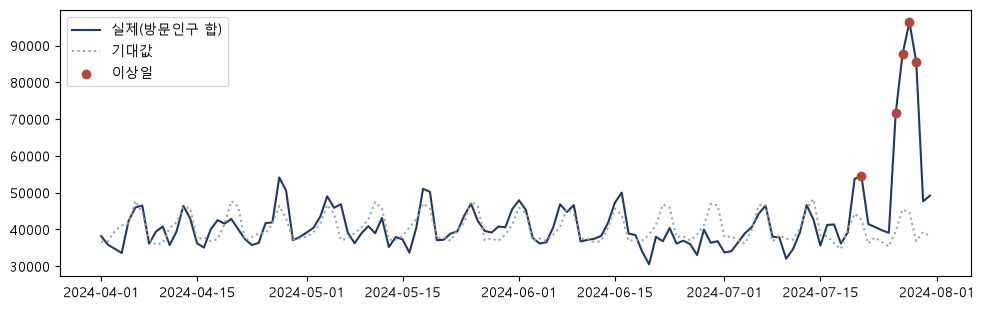

In [6]:
from app.analytics.detect import score_series
s = st.series("유동인구", "제주시 이호동"); _, exp, z = score_series(s, "seasonal_z")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(s.index, s.values, color="#1F3A5F", label="실제(방문인구 합)"); ax.plot(exp.index, exp.values, ":", color="#9AA5B1", label="기대값")
hit = z[z.abs() >= 3.5].dropna(); ax.scatter(hit.index, s.reindex(hit.index), color="#B5473A", zorder=3, label="이상일")
ax.legend(); plt.tight_layout()

**읽은 것**
- 5/5~5/6(어린이날·대체공휴일)과 6/7(현충일 다음 날인 금요일)에 여러 읍면동이 동시에 증가 → '공휴일·연휴' 원인 후보
- 7월 말 이호동·애월읍·한림읍 등 해변 지역의 여러 날 연속 증가 → '지속 변화'(여름 성수기 시작) — 하루짜리 급변과 구분해 보고
- 두 방법이 잡는 날이 다르다 → 가짜 이상 주입 평가로 어느 쪽을 기본으로 쓸지 정한다(Task 9)
- 한계: 4개월치라 연 단위 계절성은 반영하지 못함, 시리즈 끝(7/31)은 앞쪽 데이터만으로 기준선을 잡음